In [7]:
import numpy as np 
import matplotlib.pyplot as plt
from hcipy import *
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [8]:
#importing the onsky filtered field cube
fields = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_filtered_fields.fits')

In [9]:
def moving_average(a, n=10):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+2*std) & (data > mean-2*std))
    return data[indices]

In [10]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [22]:
print(len(fields))

8855


In [11]:
#now doing calculations for the cube, but cutting it off near the beginning because that's all we need
fields_trimmed = fields[0:1000]

ADC.set_control_mtx(np.array([0.21178766, 0.19275196]))
disps = np.zeros(len(fields_trimmed))
commands = []
speckle_angles = []
pointings = []

for i, field in enumerate(fields_trimmed):
    ADC.set_psf(field)
    angles = ADC.find_speckle_angles2()
    pairs = ADC.speckle_pairs(angles)
    speckle_angles.append(angles)
    pointings.append(pairs)
    commands.append(ADC.calculate_command(pairs))

pointings = np.array(pointings)
commands = np.array(commands)

In [13]:
print(commands)

[[[ 3.86803229e-01]]

 [[ 1.24394706e+00]]

 [[ 7.39639097e-01]]

 [[ 5.67346402e+00]]

 [[ 2.94006489e+00]]

 [[-6.30767328e-01]]

 [[-1.64305133e+00]]

 [[ 8.15522588e-01]]

 [[-8.36380194e-02]]

 [[ 2.40028439e-01]]

 [[ 7.43670820e-01]]

 [[ 1.53594545e+00]]

 [[ 2.32299848e+00]]

 [[-1.62923904e-01]]

 [[ 4.92542028e-01]]

 [[ 2.24709197e+00]]

 [[-2.83046710e-01]]

 [[ 9.18928921e-01]]

 [[-6.87251168e-01]]

 [[-3.98783099e-01]]

 [[ 7.70232330e-02]]

 [[ 1.87336023e-01]]

 [[-3.79837977e-02]]

 [[ 1.00838026e-01]]

 [[-2.43491483e-02]]

 [[-1.47408736e-01]]

 [[-5.71338172e-02]]

 [[ 4.76012503e-01]]

 [[-1.33542380e+00]]

 [[ 4.21900643e-01]]

 [[-1.35996708e+00]]

 [[ 5.79661967e-01]]

 [[ 9.91374177e-01]]

 [[ 3.94667522e-01]]

 [[ 7.84752274e-01]]

 [[-2.68281350e-01]]

 [[-2.36958709e-01]]

 [[ 2.29827072e-01]]

 [[ 1.66541301e-01]]

 [[ 6.54010495e-01]]

 [[-6.09146022e-01]]

 [[ 1.63120542e+00]]

 [[ 2.46664807e-01]]

 [[-3.24805116e-01]]

 [[-4.29667435e-01]]

 [[ 1.3750

In [14]:
np.savetxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/2025A_analysis/pointings/onsky_i_pointings.csv',pointings[0],delimiter=',')
np.savetxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/2025A_analysis/pointings/onsky_i_commands.csv',np.squeeze(commands),delimiter=',')

In [ ]:
print(len(commands))
print(len(pointings))

2000
2000


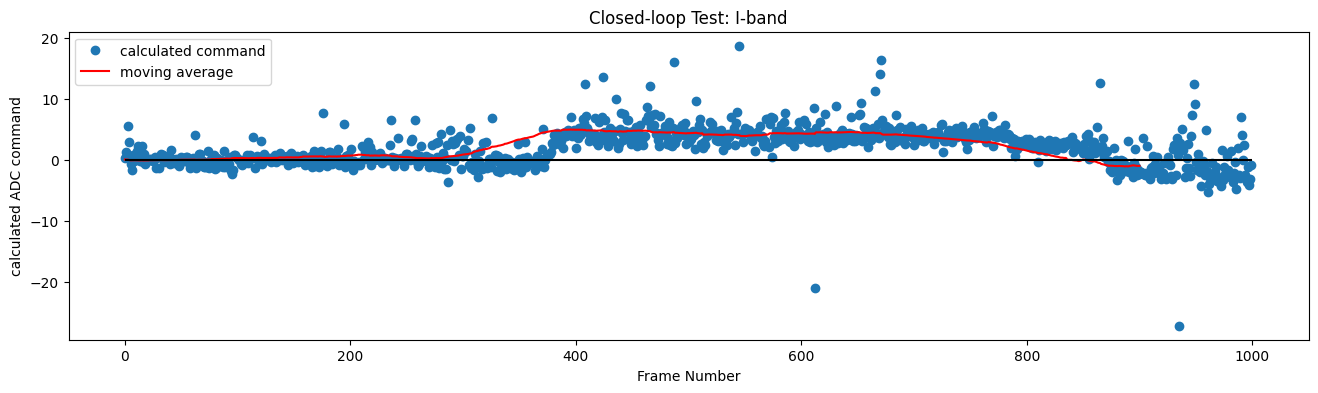

In [15]:
avg = moving_average(commands,n=100)

plt.figure(figsize=(16,4))
plt.plot(np.squeeze(commands),'o',label='calculated command')
plt.plot(avg,'-',label='moving average',color='red')
plt.hlines(0,0,len(commands),'black')
plt.xlabel('Frame Number')
plt.ylabel('calculated ADC command')
plt.title('Closed-loop Test: I-band')
plt.legend()

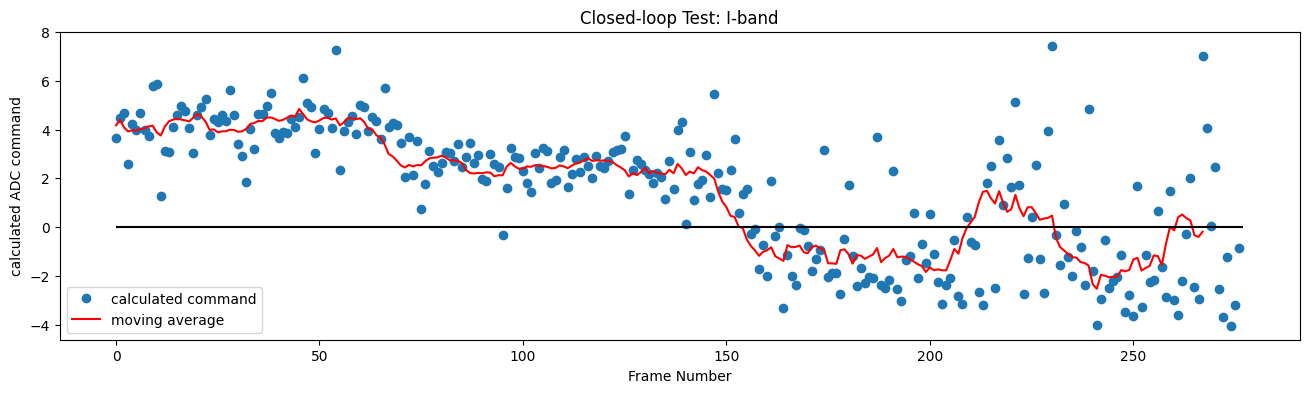

In [21]:
all_commands = reject_outliers(np.squeeze(commands))[700:1000]
avg = moving_average(all_commands,n=10)

plt.figure(figsize=(16,4))
plt.plot(np.squeeze(all_commands),'o',label='calculated command')
plt.plot(avg,'-',label='moving average',color='red')
plt.hlines(0,0,len(all_commands),'black')
plt.xlabel('Frame Number')
plt.ylabel('calculated ADC command')
plt.title('Closed-loop Test: I-band')
plt.legend()

In [ ]:
#gotta pare this down by averaging!


In [ ]:
print(avg[500])
#so yeah, definitely the wrong response matrix. but I can try and do what i want with this data and then figure out which response matrix is the correct one at the end

7.128178769973962


In [ ]:
descent = all_commands[400:1000]
descent_rav = avg[400:1000]
plt.plot(descent,'o-',alpha=0.7)
plt.plot(descent_rav)
plt.hlines(0,0,600,colors='black')
plt.show()

NameError: name 'all_commands' is not defined